In [1]:
import pandas as pd
import numpy as np

In [2]:
df= pd.read_csv("powerplant_data.csv")

In [5]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [6]:
X=df.drop("PE",axis=1)
y=df["PE"]

In [10]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [16]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [18]:
X_test_scaled

array([[ 1.34499288,  0.23869298, -1.28658067, -1.10532538],
       [ 0.81095912,  1.36269098, -0.74140656,  0.26485915],
       [-0.2437241 , -0.73900436,  1.99970178, -0.19713193],
       ...,
       [-0.67068342, -1.15902881, -0.29951077, -0.10651852],
       [ 1.31420898,  1.33752097, -0.87346737, -0.44288647],
       [-0.2611237 , -0.27021304,  0.37433797,  1.10646548]],
      shape=(1914, 4))

In [22]:
import torch
import torch.nn as nn
X_train_tensor=torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor=torch.tensor(y_train.values, dtype=torch.float32).view(-1,1)
X_test_tensor=torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor=torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)

In [23]:
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
test_dataset = TensorDataset(X_test_tensor,y_test_tensor)

In [24]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=32)

In [39]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()
        self.model = nn.Sequential(
        #1st hidden layer
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),
            
        #2st hidden layer
            nn.Linear(6,6),
            nn.ReLU(),
        #output
            nn.Linear(6,1),
        )

    def forward(self, x):
        return self.model(x)

In [40]:
import torch.optim as optim
model = ANN()
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [41]:
train_losses=[]
val_losses=[]
best_val_loss=float("inf")
epochs = 100
for epoch in range(epochs):
    model.train()
    running_loss=0.0

    for xb,yb in train_loader:
        optimizer.zero_grad()
        outputs = model(xb)
        loss=crietrion(outputs,yb)
        loss.backward()
        optimizer.step()
        running_loss+=loss.item()
    epoch_train_loss = running_loss/len(train_loader)
    train_losses.append(epoch_train_loss) 

    model.eval()
    running_val_loss=0.0
    with torch.no_grad():
        for xb,yb in test_loader:
            outputs = model(xb)
            loss=crietrion(outputs,yb)
            running_val_loss+=loss

    epoch_val_loss = running_val_loss/len(test_loader)
    val_losses.append(epoch_val_loss)
    print(f"epoch {epoch+1}/{epochs} ==> training loss = {epoch_train_loss} & validation loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss=epoch_val_loss
        torch.save(model.state_dict(),"best_model.pt")

epoch 1/100 ==> training loss = 206009.9078125 & validation loss = 203069.65625
epoch 2/100 ==> training loss = 192863.11529947916 & validation loss = 175780.96875
epoch 3/100 ==> training loss = 146890.49765625 & validation loss = 112941.03125
epoch 4/100 ==> training loss = 79272.21910807291 & validation loss = 49485.33984375
epoch 5/100 ==> training loss = 32834.4792195638 & validation loss = 21999.607421875
epoch 6/100 ==> training loss = 18014.416569010416 & validation loss = 15235.55859375
epoch 7/100 ==> training loss = 13389.617374674479 & validation loss = 11598.7080078125
epoch 8/100 ==> training loss = 10055.652768961589 & validation loss = 8458.4833984375
epoch 9/100 ==> training loss = 7220.634666951498 & validation loss = 5893.35888671875
epoch 10/100 ==> training loss = 4903.540831502279 & validation loss = 3924.97021484375
epoch 11/100 ==> training loss = 3219.189725748698 & validation loss = 2503.8447265625
epoch 12/100 ==> training loss = 2016.1919914245605 & validati

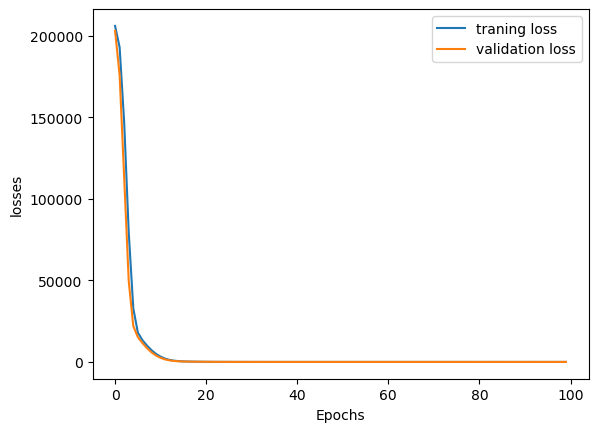

In [42]:
import matplotlib.pyplot as plt
loss_df=pd.DataFrame({
    "train_loss":train_losses,
    "val_loss":val_losses
})
plt.plot(loss_df["train_loss"],label="traning loss")
plt.plot(loss_df["val_loss"],label="validation loss")
plt.xlabel("Epochs")
plt.ylabel("losses")
plt.legend()

In [43]:
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [45]:
model.eval()
with torch.no_grad():
    train_pred=model(X_train_tensor)
    test_pred=model(X_test_tensor)

    train_mse_loss=crietrion(train_pred,y_train_tensor)
    test_mse_loss=crietrion(test_pred,y_test_tensor)

print("Training MSE:",train_mse_loss.item())
print("Testing MSE:",test_mse_loss.item())

Training MSE: 20.657352447509766
Testing MSE: 18.913803100585938


In [46]:
from sklearn.metrics import r2_score
print("r^2 score:",r2_score(y_test,test_pred))

r^2 score: 0.9339011332763993


In [51]:
predicted_df=pd.DataFrame(test_pred.numpy(),columns=["predicted values"])
actual_df=pd.DataFrame(y_test.values,columns=["actual values"])
pd.concat([predicted_df,actual_df],axis=1)

,predicted values,actual values
0,435.068665,433.27
1,436.982239,438.16
2,461.909851,458.42
3,476.889771,480.82
4,435.674683,441.41
...,...,...
1909,451.339569,456.70
1910,431.608887,438.04
1911,467.425507,467.80
1912,431.092773,437.14
